In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from hcipy import *
from psfGenerator import PsfGenerator
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from adcFitter_onsky import AdcFitter

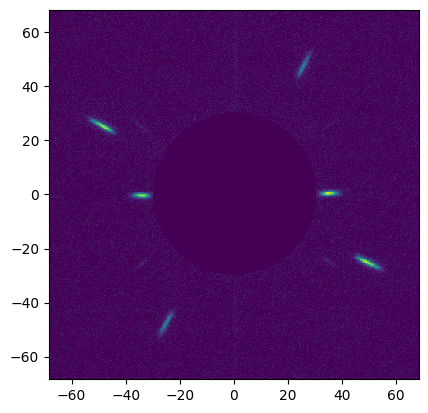

In [2]:
fieldcube = read_field('/Users/Katie/Documents/Fall 2023/MagAO-X/ADC Sim code/updated onsky/all_lab_fields_i.fits')
img = fieldcube[0]
imshow_field(img)

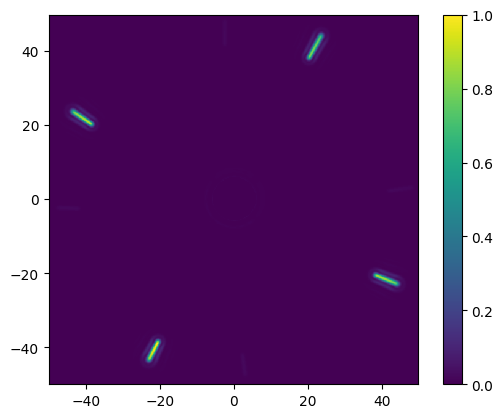

In [3]:
wavelength = 764E-9
bw = 120E-9
wavelength_normalized = wavelength / 656E-9
bw_normalized = bw / wavelength
grating_angle = 28
grating_freq = 40

ADC = AdcFitter(wavelength=wavelength,bandwidth=bw)

PsfGen = PsfGenerator(center_wavelength=wavelength_normalized,bandwidth=bw_normalized, focal_sampling=6, focal_extent=50,grating_angle=grating_angle, fx=grating_freq, fy = grating_freq, mask=True)
disp_x = np.random.rand() * 0.05
disp_y = np.random.rand() * 0.05

psf = PsfGen.psf(magnitude_x=disp_x,magnitude_y=disp_y)
ADC.set_psf(psf)

imshow_field(ADC.psf)
plt.colorbar()

In [4]:
#let's look at the fit visually
def visualize_fit(image):
    speckle_angles = np.zeros(4)
    sig_x = [1,3.5,1,3.5]
    sig_y = [3.5,1,3.5,1]
    fit_image = image - image

    for i in range(4):
        img = ADC.find_speckle(ADC.psf,i)
        ADC.current_speckle = i
        ADC.set_measurement(img)

        sigma_x = sig_x[i]
        sigma_y = sig_y[i]
        #orientation = np.radians(28)

        orientation = ADC.estimate_angle()
        if ADC.current_speckle == 0 or ADC.current_speckle ==2:
            orientation = np.pi/2 - orientation
        elif ADC.current_speckle == 1 or ADC.current_speckle == 3:
            orientation = -orientation

        #params common to all four
        amplitude = ADC.data.max()
        centroid = ADC.estimate_centroid()
        mu_x = centroid[0]
        mu_y = centroid[1]
        background = 0

        theta_est = np.array([amplitude, mu_x, mu_y, sigma_x, sigma_y, orientation, background])
        fit = ADC.fit(theta_est) 
        theta = fit.x
        speckle_angles[i] = np.degrees(fit.x[5])
        fit_image = fit_image + ADC.satellite_spot(*theta)(image.grid)

    ADC.current_speckle = None
    speckle_angles = np.array(speckle_angles).T

    return fit_image

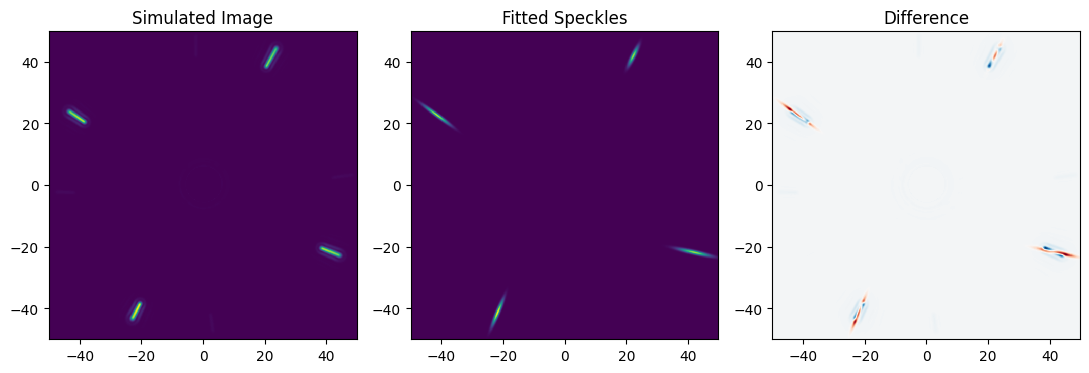

In [5]:
fitted = visualize_fit(ADC.psf)

plt.figure(figsize=(11,5))
plt.subplot(1,3,1)
imshow_field(ADC.psf)
plt.title('Simulated Image')
plt.subplot(1,3,2)
imshow_field(fitted)
plt.title('Fitted Speckles')
plt.subplot(1,3,3)
imshow_field(ADC.psf - fitted,cmap='RdBu')
plt.title('Difference')
plt.tight_layout()
plt.show()

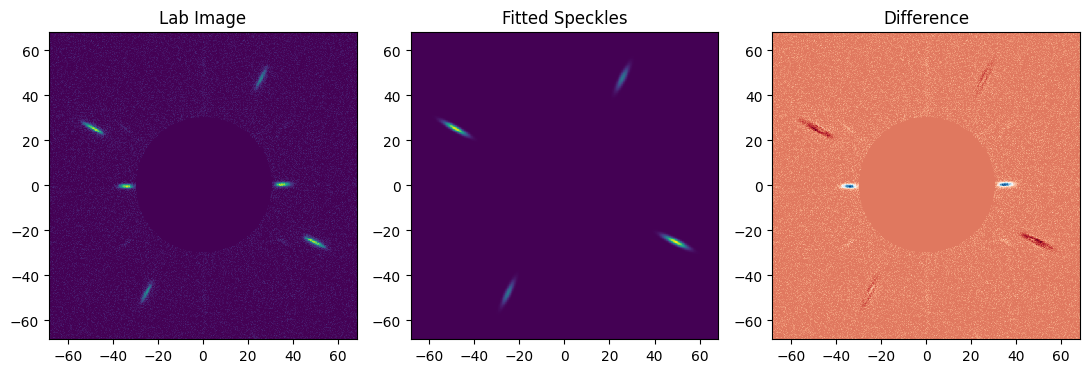

In [6]:
#same thing,but with a real lab image
ADC.set_psf(img)
real_fitted = visualize_fit(img)

plt.figure(figsize=(11,5))
plt.subplot(1,3,1)
imshow_field(img)
plt.title('Lab Image')
plt.subplot(1,3,2)
imshow_field(real_fitted)
plt.title('Fitted Speckles')
plt.subplot(1,3,3)
imshow_field(img - real_fitted,cmap='RdBu')
plt.title('Difference')
plt.tight_layout()
plt.show()

In [7]:
#now let's see if there's bias in the simulated images if we use zero dispersion and introduce some poisson noise:
pairs = []
num_photons = 1E6

for i in range(100):
    psf = PsfGen.noisy_turbulent_psf(magnitude_x=0,magnitude_y=0,num_photons=num_photons,ptv=0)
    ADC.set_psf(psf)

    angles = ADC.find_speckle_angles2()
    pair = ADC.speckle_pairs(angles)
    pairs.append(pair)

    if np.abs(np.any(pair)) > 10:
        break

pairs = np.matrix(pairs)

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/hcipy/optics/aberration.py:37: RuntimeWarning: divide by zero encountered in power
  res = Field(grid.as_('polar').r**exponent, grid)


In [8]:
print(angles)
print(f'mean offset: {np.mean(pairs,axis=0)}°')
print(f'sd of pointing offsets: {np.std(pairs,axis=0)}°')

[24.58599705 25.32014932 24.95875417 24.71267956]
mean offset: [[-0.34992936  0.08232691]]°
sd of pointing offsets: [[2.82371855 3.42579325]]°


mean offset: [[-0.34992936  0.08232691]]°
sd of pointing offsets: [[2.82371855 3.42579325]]°


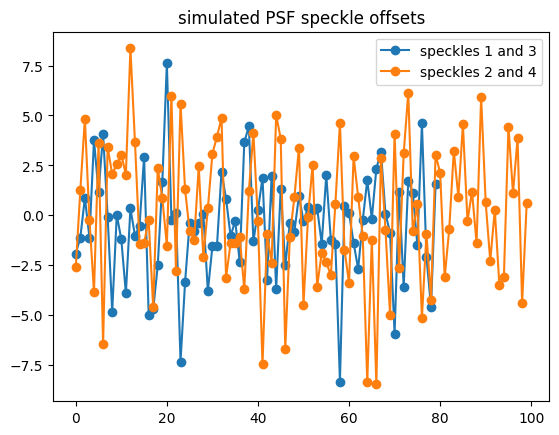

In [9]:
print(f'mean offset: {np.mean(pairs,axis=0)}°')
print(f'sd of pointing offsets: {np.std(pairs,axis=0)}°')

plt.plot(pairs[0:80,0],'o-',label='speckles 1 and 3')
plt.plot(pairs[:,1],'o-',label='speckles 2 and 4')
plt.title('simulated PSF speckle offsets')
plt.legend()
plt.show()

In [10]:
def reject_outliers(data):
    std = np.nanstd(data)
    mean = np.nanmean(data)
    indices = np.where((data < mean+1*std) & (data > mean-2*std)) #the indicies of numbers we're NOT rejecting
    return data[indices]

pairs = reject_outliers(pairs)